# EDA — PM2.5 trạm trên lưới 0,05°

Dữ liệu: `/home/slow_data/Air_Quality/AQI/process/aqi_pm25_grid_daily.pkl` do `pm25_map/features/build_grid/map_aqi_grid.py` sinh ra.
Một dòng = một (ô 0,05°, ngày địa phương UTC+7). Giá trị ô = trung bình các **trạm** trong ô, mỗi trạm = trung bình các giờ có số liệu trong ngày.

Mục lục: 1. Tổng quan · 2. Không gian · 3. Thời gian · 4. Phân bố PM2.5 · 5. Độ đủ giờ trong ngày · 6. Ô nhiều trạm ·
7. Mùa và chu kỳ · 8. Kiểm tra bất thường · 9. Tóm tắt

## 0. Thiết lập

In [15]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt

REPO = Path("/home/work1/projects/Air_Quality")
PROC = Path("/home/slow_data/Air_Quality/AQI/process")
d = pd.read_pickle(PROC / "aqi_pm25_grid_daily.pkl")
cells = pd.read_csv(PROC / "aqi_pm25_grid_cells.csv")
d = d.merge(cells[["cell_id", "sensor_mix", "province", "region", "in_vietnam"]], on="cell_id", how="left")
prov = gpd.read_file(REPO / "Data_Collection/GADM_Vietnam/gadm41_VNM_1.shp").to_crs("EPSG:4326")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
C_KK, C_LCS, C_MIX = "#2a78d6", "#eb6834", "#1baf7a"
MIXC = {"KK": C_KK, "LCS": C_LCS, "KK+LCS": C_MIX}
print(d.shape); d.head()

(46664, 16)


,cell_id,row,col,cell_lat,cell_lon,date,pm25,pm25_sd_stations,n_stations,n_hours_total,n_hours_min,pm25_hour_weighted,sensor_mix,province,region,in_vietnam
0,3882,24,42,22.275,104.125,2021-07-26,12.431042,0.0,1,24,24,12.431042,KK,Lào Cai,NW,True
1,3882,24,42,22.275,104.125,2021-07-27,19.804350,0.0,1,24,24,19.804350,KK,Lào Cai,NW,True
2,3882,24,42,22.275,104.125,2021-07-28,24.795213,0.0,1,24,24,24.795213,KK,Lào Cai,NW,True
3,3882,24,42,22.275,104.125,2021-07-29,20.670904,0.0,1,23,23,20.670904,KK,Lào Cai,NW,True
4,3882,24,42,22.275,104.125,2021-07-30,21.495963,0.0,1,24,24,21.495963,KK,Lào Cai,NW,True


## 1. Tổng quan

In [16]:
print(f"Số dòng (ô-ngày)      : {len(d):,}")
print(f"Số ô có trạm          : {d.cell_id.nunique()}  (bảng ô: {len(cells)})")
print(f"Khoảng ngày           : {d.date.min().date()} → {d.date.max().date()}  ({d.date.nunique():,} ngày có ≥ 1 ô)")
print(f"Trùng (cell_id, date) : {d.duplicated(['cell_id', 'date']).sum()}")
print(f"Ô ngoài lãnh thổ VN   : {(~cells.in_vietnam).sum()}")
print("\nThiếu giá trị theo cột:"); print(d.isna().sum()[d.isna().sum() > 0].to_string() or "  không có")
print("\nLoại thiết bị trong ô:"); print(cells.sensor_mix.value_counts().to_string())
print("\nSố trạm mỗi ô:"); print(cells.n_stations_total.value_counts().sort_index().to_string())
d.describe().T.round(2)

Số dòng (ô-ngày)      : 46,664
Số ô có trạm          : 80  (bảng ô: 80)
Khoảng ngày           : 2020-01-01 → 2026-06-19  (2,362 ngày có ≥ 1 ô)
Trùng (cell_id, date) : 0
Ô ngoài lãnh thổ VN   : 1

Thiếu giá trị theo cột:
Series([], )

Loại thiết bị trong ô:
sensor_mix
KK        42
LCS       33
KK+LCS     4
OTHER      1

Số trạm mỗi ô:
n_stations_total
1    63
2    11
3     4
4     1
5     1


,count,mean,min,25%,50%,75%,max,std
cell_id,46664.0,16626.66936,3882.0,7771.0,8100.0,26856.0,44569.0,13238.176415
row,46664.0,103.338034,24.0,48.0,50.0,167.0,278.0,82.668684
col,46664.0,92.583983,42.0,78.0,86.0,102.0,144.0,20.798241
cell_lat,46664.0,18.308098,9.575,15.125,20.975,21.075,22.275,4.133434
cell_lon,46664.0,106.654199,104.125,105.925,106.325,107.125,109.225,1.039912
date,46664,2024-03-20 04:16:15.141436672,2020-01-01 00:00:00,2022-11-07 00:00:00,2024-08-26 00:00:00,2025-11-07 00:00:00,2026-06-19 00:00:00,NaN
pm25,46664.0,25.970326,3.054372,11.579252,18.836447,31.666477,243.051595,22.762356
pm25_sd_stations,46664.0,0.6544,0.0,0.0,0.0,0.0,78.380037,3.346081
n_stations,46664.0,1.108928,1.0,1.0,1.0,1.0,5.0,0.409458
n_hours_total,46664.0,25.773016,12.0,24.0,24.0,24.0,120.0,9.959229


## 2. Phân bố không gian

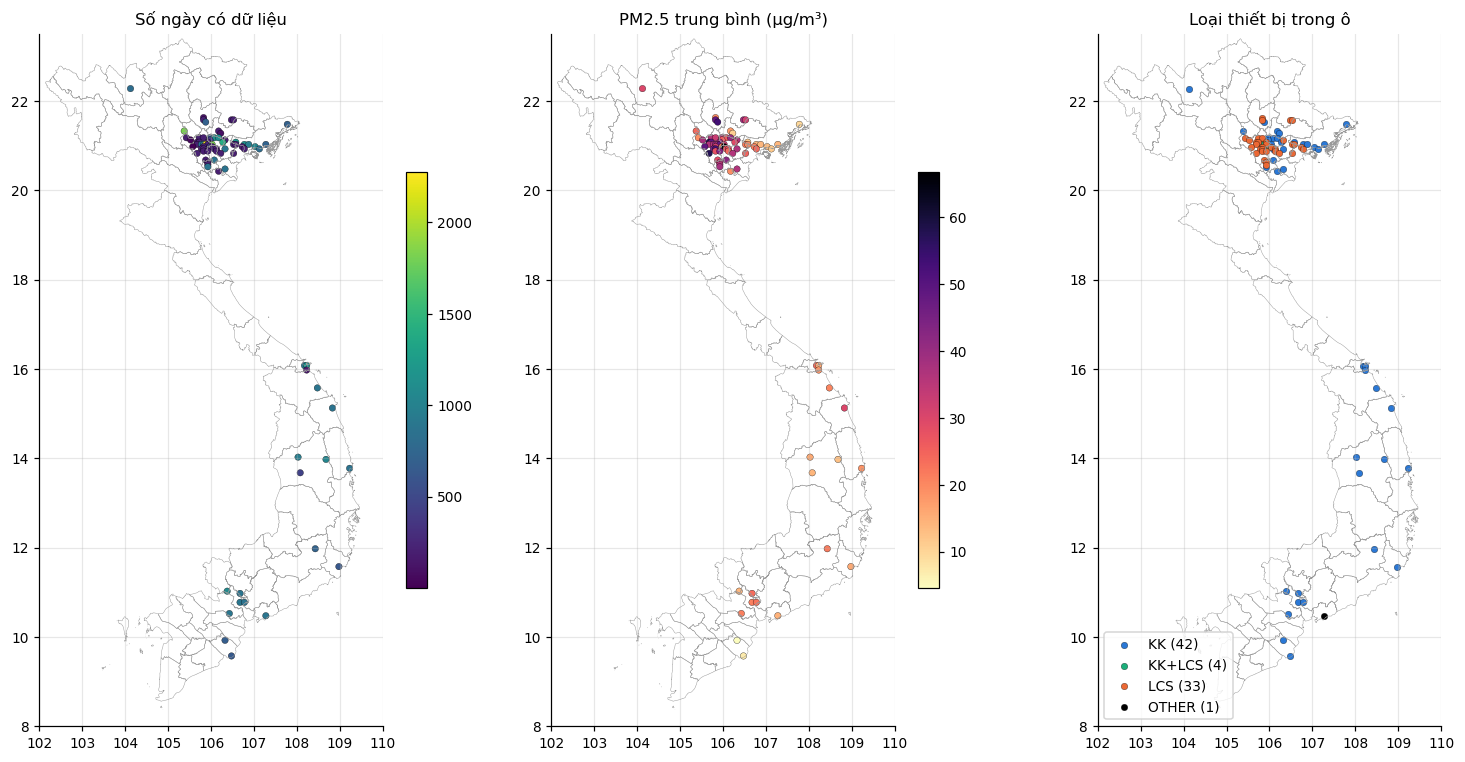

         o  ngay_TB  pm25_TB
region                      
CH       4    790.5     16.0
NE      16    642.9     22.3
NW       1    807.0     29.9
RRD     44    457.8     35.7
SCC      7    778.6     20.3
SE       8    852.0     16.1


In [17]:
per = d.groupby("cell_id").agg(n_days=("date", "size"), pm25=("pm25", "mean"), first=("date", "min"),
                               last=("date", "max")).join(cells.set_index("cell_id"))
fig, axs = plt.subplots(1, 3, figsize=(14, 7))
for ax, col, title, cmap in ((axs[0], "n_days", "Số ngày có dữ liệu", "viridis"),
                             (axs[1], "pm25", "PM2.5 trung bình (µg/m³)", "magma_r")):
    prov.boundary.plot(ax=ax, color="0.6", lw=0.3)
    sc = ax.scatter(per.cell_lon, per.cell_lat, c=per[col], s=18, cmap=cmap, edgecolor="k", lw=0.2)
    plt.colorbar(sc, ax=ax, shrink=0.6); ax.set_title(title); ax.set_xlim(102, 110); ax.set_ylim(8, 23.5)
prov.boundary.plot(ax=axs[2], color="0.6", lw=0.3)
for k, g in per.groupby("sensor_mix"):
    axs[2].scatter(g.cell_lon, g.cell_lat, s=18, color=MIXC.get(k, "k"), label=f"{k} ({len(g)})", edgecolor="k", lw=0.2)
axs[2].legend(); axs[2].set_title("Loại thiết bị trong ô"); axs[2].set_xlim(102, 110); axs[2].set_ylim(8, 23.5)
plt.tight_layout(); plt.show()
print(per.groupby("region").agg(o=("n_days", "size"), ngay_TB=("n_days", "mean"), pm25_TB=("pm25", "mean")).round(1))

In [18]:
# Mật độ: bao nhiêu ô có trạm trong mỗi tỉnh (top 15)
per.province.value_counts().head(15)

province
Hà Nội         20
Quảng Ninh      8
Hưng Yên        6
Bắc Ninh        6
Hải Dương       5
Thái Nguyên     3
Hà Nam          3
Đà Nẵng         3
Gia Lai         3
Hải Phòng       2
Lạng Sơn        2
Hồ Chí Minh     2
Trà Vinh        2
Bắc Giang       2
Lào Cai         1
Name: count, dtype: int64

## 4. Phân bố PM2.5

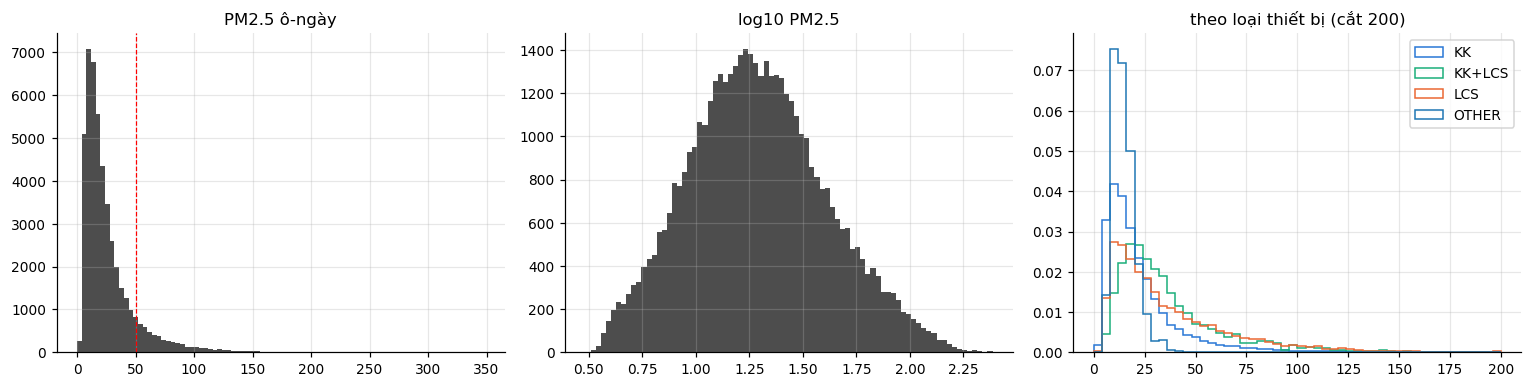

Phân vị: {0.0: 3.1, 0.01: 4.2, 0.05: 6.0, 0.25: 11.6, 0.5: 18.8, 0.75: 31.7, 0.95: 72.2, 0.99: 116.4, 0.999: 169.5, 1.0: 243.1}
> 50 µg/m³ (QCVN 05:2023 24h): 11.3% · > 150: 107 ô-ngày
              count  mean   std  min   25%   50%   75%    max
sensor_mix                                                   
KK          35143.0  23.0  20.0  3.1  10.6  17.1  27.9  238.8
KK+LCS       4443.0  36.6  25.6  4.2  19.1  29.4  45.2  221.3
LCS          6190.0  36.6  29.8  3.5  15.1  27.0  49.1  243.1
OTHER         888.0  14.7   5.6  5.9  10.5  13.7  17.5   41.9


In [19]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
axs[0].hist(d.pm25, bins=np.arange(0, 352, 4), color="0.3"); axs[0].set_title("PM2.5 ô-ngày"); axs[0].axvline(50, color="r", ls="--", lw=0.8)
axs[1].hist(np.log10(d.pm25), bins=80, color="0.3"); axs[1].set_title("log10 PM2.5")
for k, g in d.groupby("sensor_mix"):
    axs[2].hist(g.pm25.clip(upper=200), bins=np.arange(0, 202, 4), histtype="step", density=True, color=MIXC.get(k), label=k)
axs[2].legend(); axs[2].set_title("theo loại thiết bị (cắt 200)"); plt.tight_layout(); plt.show()
q = d.pm25.quantile([0, .01, .05, .25, .5, .75, .95, .99, .999, 1]).round(1)
print("Phân vị:", q.to_dict())
print(f"> 50 µg/m³ (QCVN 05:2023 24h): {(d.pm25 > 50).mean():.1%} · > 150: {(d.pm25 > 150).sum()} ô-ngày")
print(d.groupby("sensor_mix").pm25.describe().round(1))

## 5. Độ đủ giờ trong ngày
`n_hours_total` = tổng số giờ của mọi trạm trong ô; `n_hours_min` = số giờ của trạm ít giờ nhất. Bài Li et al. 2020 chỉ dùng ngày có ≥ 18 giờ hợp lệ.

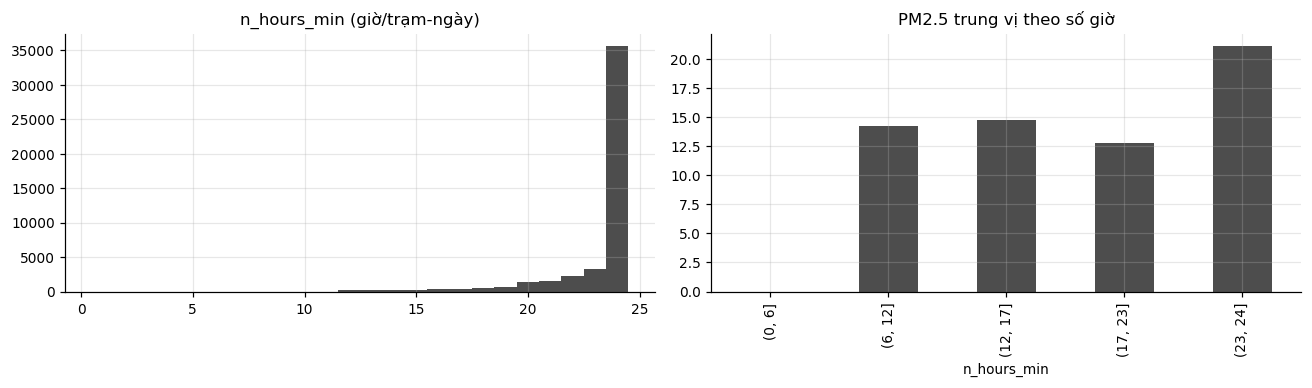

Giữ nếu n_hours_min ≥ 12: 100.0% số ô-ngày
Giữ nếu n_hours_min ≥ 18: 96.6% số ô-ngày
Giữ nếu n_hours_min ≥ 24: 76.3% số ô-ngày
               count  mean   std  min   25%   50%   75%    max
n_hours_min                                                   
(0, 6]           0.0   NaN   NaN  NaN   NaN   NaN   NaN    NaN
(6, 12]        194.0  21.0  21.3  3.8   9.7  14.2  23.1  132.5
(12, 17]      1405.0  20.6  18.7  3.5  10.1  14.7  24.3  148.0
(17, 23]      9456.0  18.6  19.0  3.1   8.2  12.8  20.8  243.1
(23, 24]     35609.0  28.2  23.4  3.4  13.1  21.1  34.5  238.8


In [20]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].hist(d.n_hours_min, bins=np.arange(0.5, 25.5, 1), color="0.3"); axs[0].set_title("n_hours_min (giờ/trạm-ngày)")
b = pd.cut(d.n_hours_min, [0, 6, 12, 17, 23, 24])
d.groupby(b).pm25.median().plot.bar(ax=axs[1], color="0.3"); axs[1].set_title("PM2.5 trung vị theo số giờ")
plt.tight_layout(); plt.show()
for h in (12, 18, 24):
    print(f"Giữ nếu n_hours_min ≥ {h:2d}: {(d.n_hours_min >= h).mean():.1%} số ô-ngày")
print(d.groupby(b).pm25.describe().round(1))

## 6. Ô có nhiều trạm
Độ lệch giữa các trạm trong cùng ô, cùng ngày = sai số đại diện của ô ~5,5 km (sàn sai số của mọi bản đồ một giá trị/ô).

Ô-ngày có ≥ 2 trạm: 3,974 (8.5%) ở 17 ô
            pm25_sd_stations    cv
sensor_mix                        
KK                      4.60  0.21
KK+LCS                  7.82  0.26
LCS                     4.35  0.15


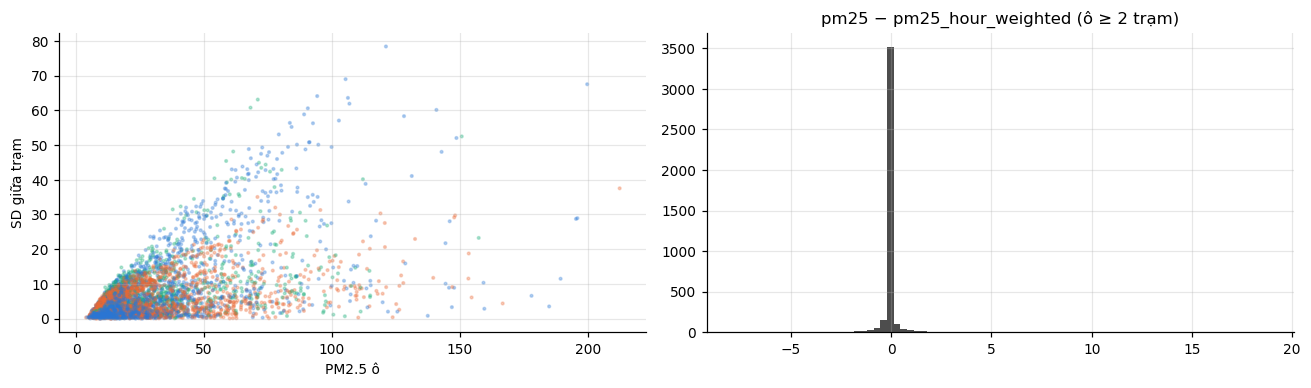

|pm25 − hour_weighted| > 5 µg/m³: 11 ô-ngày


In [21]:
m = d[d.n_stations >= 2].copy()
m["cv"] = m.pm25_sd_stations / m.pm25
print(f"Ô-ngày có ≥ 2 trạm: {len(m):,} ({len(m)/len(d):.1%}) ở {m.cell_id.nunique()} ô")
print(m.groupby("sensor_mix")[["pm25_sd_stations", "cv"]].median().round(2))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].scatter(m.pm25, m.pm25_sd_stations, s=3, alpha=0.3, c=m.sensor_mix.map(MIXC)); axs[0].set_xlabel("PM2.5 ô"); axs[0].set_ylabel("SD giữa trạm")
diff = d.pm25 - d.pm25_hour_weighted
axs[1].hist(diff[d.n_stations >= 2], bins=80, color="0.3"); axs[1].set_title("pm25 − pm25_hour_weighted (ô ≥ 2 trạm)")
plt.tight_layout(); plt.show()
print(f"|pm25 − hour_weighted| > 5 µg/m³: {(diff.abs() > 5).sum()} ô-ngày")

## 7. Mùa và chu kỳ

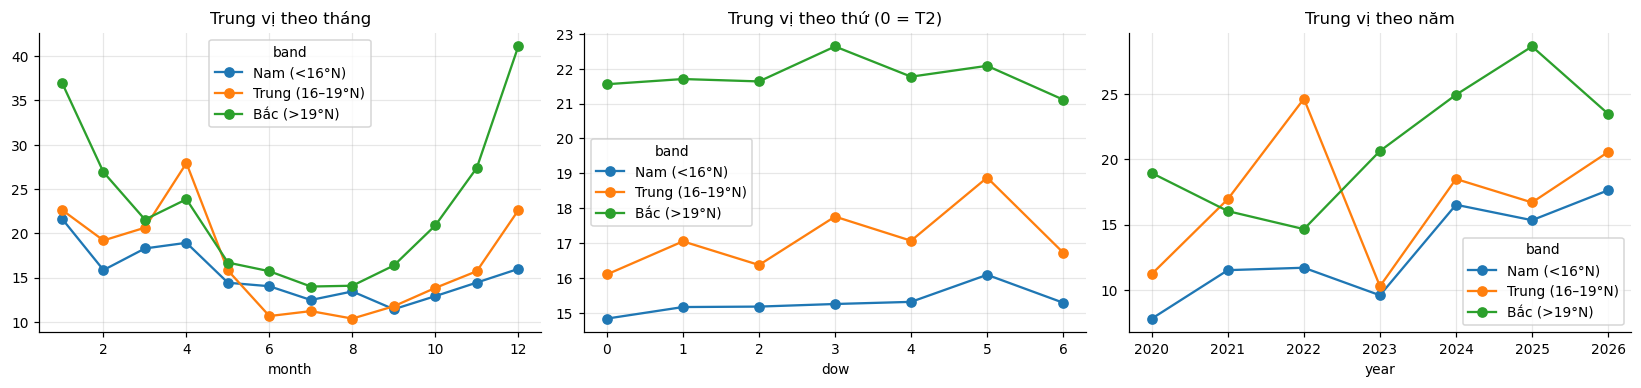

In [22]:
d["month"], d["dow"], d["year"] = d.date.dt.month, d.date.dt.dayofweek, d.date.dt.year
d["band"] = pd.cut(d.cell_lat, [8, 16, 19, 23.5], labels=["Nam (<16°N)", "Trung (16–19°N)", "Bắc (>19°N)"])
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
d.groupby(["month", "band"]).pm25.median().unstack().plot(ax=axs[0], marker="o"); axs[0].set_title("Trung vị theo tháng")
d.groupby(["dow", "band"]).pm25.median().unstack().plot(ax=axs[1], marker="o"); axs[1].set_title("Trung vị theo thứ (0 = T2)")
d.groupby(["year", "band"]).pm25.median().unstack().plot(ax=axs[2], marker="o"); axs[2].set_title("Trung vị theo năm")
plt.tight_layout(); plt.show()

## 8. Kiểm tra bất thường

In [23]:
# 8.1 Giá trị dính ở biên lọc của filter_aqi.py (PM2.5 ∈ [3, 350] theo giờ)
print("ô-ngày PM2.5 < 4 :", (d.pm25 < 4).sum(), "· > 300 :", (d.pm25 > 300).sum())
# 8.2 Giá trị đứng yên: ô 1 trạm có ≥ 3 ngày liên tiếp cùng một giá trị (làm tròn 0,01)
s1 = d[d.n_stations == 1].sort_values(["cell_id", "date"]).copy()
s1["v"] = s1.pm25.round(2)
s1["new"] = (s1.v != s1.groupby("cell_id").v.shift()) | (s1.date.diff().dt.days != 1)
s1["run"] = s1.groupby("cell_id").new.cumsum()
runs = s1.groupby(["cell_id", "run"]).agg(len_=("v", "size"), v=("v", "first"), start=("date", "min"))
stuck = runs[runs.len_ >= 3].sort_values("len_", ascending=False)
print(f"Chuỗi đứng yên ≥ 3 ngày: {len(stuck)} chuỗi ở {stuck.index.get_level_values(0).nunique()} ô"); stuck.head(10)

ô-ngày PM2.5 < 4 : 266 · > 300 : 0
Chuỗi đứng yên ≥ 3 ngày: 0 chuỗi ở 0 ô


,,len_,v,start
cell_id,run,,,


In [24]:
# 8.3 Gai đột biến: > 3× trung vị trượt 15 ngày của chính ô đó và > 100 µg/m³
s = d.sort_values(["cell_id", "date"]).copy()
s["med15"] = s.groupby("cell_id").pm25.transform(lambda x: x.rolling(15, center=True, min_periods=5).median())
spk = s[(s.pm25 > 3 * s.med15) & (s.pm25 > 100)]
print(f"Gai: {len(spk)} ô-ngày ở {spk.cell_id.nunique()} ô; trong đó n_hours_min < 12: {(spk.n_hours_min < 12).sum()}")
spk[["cell_id", "province", "sensor_mix", "date", "pm25", "med15", "n_hours_min", "n_stations"]].sort_values("pm25", ascending=False).head(12)

Gai: 35 ô-ngày ở 16 ô; trong đó n_hours_min < 12: 0


,cell_id,province,sensor_mix,date,pm25,med15,n_hours_min,n_stations
7484,7443,Bắc Ninh,KK,2020-02-20,231.840722,42.889138,23,1
7485,7443,Bắc Ninh,KK,2020-02-21,201.679533,42.889138,24,1
16841,7920,Bắc Ninh,KK,2020-02-21,195.875975,42.442971,24,2
16840,7920,Bắc Ninh,KK,2020-02-20,195.333716,42.442971,23,2
7486,7443,Bắc Ninh,KK,2020-02-22,178.239262,42.889138,24,1
9427,7754,Hà Nội,LCS,2026-02-05,154.546867,46.035965,24,2
1780,6317,Thái Nguyên,KK,2025-03-10,151.132017,31.383567,24,1
7898,7443,Bắc Ninh,KK,2021-06-06,149.526304,37.438862,24,1
16842,7920,Bắc Ninh,KK,2020-02-22,146.834600,42.442971,24,2
30937,9686,Thái Bình,KK,2026-01-26,146.586296,42.285425,24,1


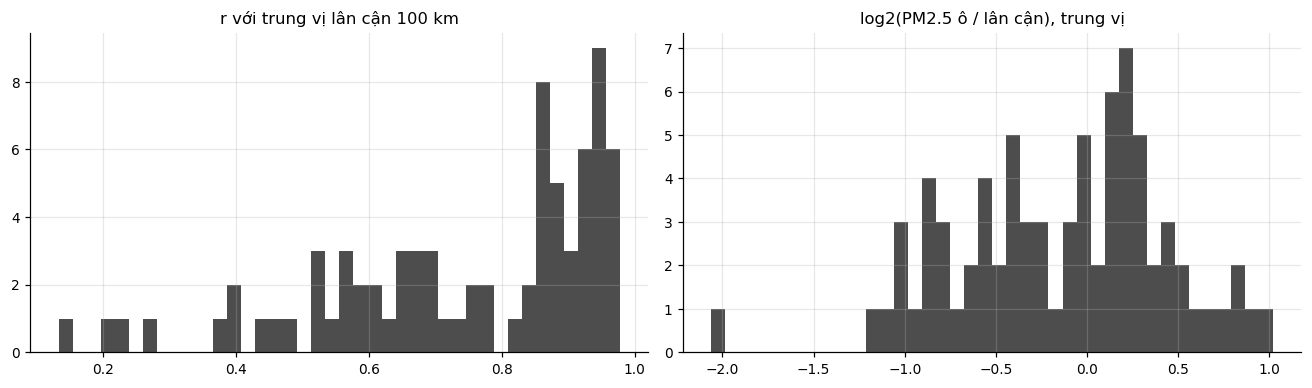

77 ô có lân cận đủ dài · r < 0,5: 10 · lệch mức > 2 lần: 6


,n_neigh,n_days,r,ratio,province,sensor_mix
cell_id,,,,,,
8100,23,1049,0.13,0.82,Quảng Ninh,KK
8262,17,798,0.21,0.76,Quảng Ninh,KK
6515,3,609,0.23,0.77,Quảng Ninh,KK
7945,11,702,0.28,0.81,Quảng Ninh,KK
7935,35,1135,0.38,0.54,Quảng Ninh,KK
43446,2,516,0.40,0.24,Trà Vinh,KK
7771,53,1177,0.41,0.48,Quảng Ninh,KK
26856,1,827,0.44,1.24,Quảng Ngãi,KK
7937,30,955,0.46,0.54,Quảng Ninh,KK


In [25]:
# 8.4 Ô lệch pha với khu vực: tương quan của ô với trung vị các ô khác trong bán kính 100 km
from scipy.spatial import cKDTree
piv = d.pivot_table(index="date", columns="cell_id", values="pm25")
xy = per[["cell_lon", "cell_lat"]].loc[piv.columns].values
tree = cKDTree(np.c_[xy[:, 0] * np.cos(np.radians(16)), xy[:, 1]] * 111.0)
rows = []
for j, cid in enumerate(piv.columns):
    nb = [k for k in tree.query_ball_point(tree.data[j], 100) if k != j]
    if not nb: continue
    ref = piv.iloc[:, nb].median(axis=1)
    ok = piv[cid].notna() & ref.notna()
    if ok.sum() >= 60:
        rows.append((cid, len(nb), ok.sum(), np.corrcoef(piv[cid][ok], ref[ok])[0, 1], (piv[cid][ok] / ref[ok]).median()))
nbr = pd.DataFrame(rows, columns=["cell_id", "n_neigh", "n_days", "r", "ratio"]).set_index("cell_id").join(per[["province", "sensor_mix"]])
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].hist(nbr.r, bins=40, color="0.3"); axs[0].set_title("r với trung vị lân cận 100 km")
axs[1].hist(np.log2(nbr.ratio), bins=40, color="0.3"); axs[1].set_title("log2(PM2.5 ô / lân cận), trung vị")
plt.tight_layout(); plt.show()
print(f"{len(nbr)} ô có lân cận đủ dài · r < 0,5: {(nbr.r < 0.5).sum()} · lệch mức > 2 lần: {((nbr.ratio > 2) | (nbr.ratio < 0.5)).sum()}")
nbr[(nbr.r < 0.5) | (nbr.ratio > 2) | (nbr.ratio < 0.5)].sort_values("r").round(2)

In [26]:
# 8.5 Ô có KK và LCS cùng ô: hai loại thiết bị lệch nhau bao nhiêu?
mix = d[d.sensor_mix == "KK+LCS"]
print(f"Ô KK+LCS: {mix.cell_id.nunique()} ô, {len(mix):,} ô-ngày; SD giữa trạm trung vị {mix.pm25_sd_stations.median():.1f} µg/m³")
# 8.6 Ngày rất ít giờ mà giá trị cực trị
print("ô-ngày n_hours_min ≤ 3 và PM2.5 > 150:", ((d.n_hours_min <= 3) & (d.pm25 > 150)).sum())
# 8.7 Bước nhảy mức theo năm của từng ô (TB năm thay đổi > 2 lần giữa hai năm liền kề, cả hai năm ≥ 100 ngày)
ya = d.groupby(["cell_id", "year"]).pm25.agg(["mean", "size"]).query("size >= 100")
ya["ratio"] = ya.groupby(level=0)["mean"].transform(lambda x: x / x.shift())
jump = ya[(ya.ratio > 2) | (ya.ratio < 0.5)]
print(f"Bước nhảy mức năm > 2 lần: {len(jump)}"); jump.round(2)

Ô KK+LCS: 4 ô, 4,443 ô-ngày; SD giữa trạm trung vị 0.0 µg/m³
ô-ngày n_hours_min ≤ 3 và PM2.5 > 150: 0
Bước nhảy mức năm > 2 lần: 4


,,mean,size,ratio
cell_id,year,,,
7441,2025,14.52,227,0.42
7599,2024,15.42,164,0.43
7920,2025,19.90,210,0.40
7937,2024,16.29,175,2.03


In [27]:
# 8.8 Giá trị sát sàn 3 µg/m³ (filter_aqi.py bỏ giờ < 3): dồn ở ngày thiếu giờ và ở vài trạm
d["full"] = d.n_hours_min >= 18
print("Tỉ lệ ô-ngày PM2.5 < 4:", d.groupby("full").pm25.apply(lambda x: (x < 4).mean()).rename({False: "thiếu giờ (<18)", True: "đủ giờ (≥18)"}).round(3).to_dict())
low = d[d.pm25 < 4].merge(cells[["cell_id", "station_names"]], on="cell_id")
low.station_names.value_counts().head(8)

Tỉ lệ ô-ngày PM2.5 < 4: {'thiếu giờ (<18)': 0.009, 'đủ giờ (≥18)': 0.006}


station_names
Trà Vinh: Tp. Trà Vinh (KK)                                                                  186
Trà Vinh: xã Đông Hải, huyện Duyên Hải (KK)                                                   36
Quảng Ninh: UBND huyện Hải Hà (KK)                                                            12
Quảng Ninh: Trung tâm văn hóa thể thao Cẩm Phả, đường Trần Phú, phường Cẩm Trung (KK)          6
Quảng Ninh: Nhuệ Hổ - Đông Triều (KK) | Quảng Ninh: UBND phường Mạo Khê - Đông Triều (KK)      5
Quảng Ninh: Nhà máy tuyển than Nam Cầu Trắng - Hạ Long (KK)                                    4
Quảng Ninh: Gần KCN Cái Lân (KK)                                                               3
Gia Lai: UBND thị xã An Khê (KK)                                                               3
Name: count, dtype: int64

In [28]:
# 8.9 Hai ô 'ngoài lãnh thổ': trạm ven biển, tâm ô rơi xuống biển (không phải lỗi toạ độ)
cells.loc[~cells.in_vietnam, ["cell_id", "cell_lat", "cell_lon", "station_names"]]

,cell_id,cell_lat,cell_lon,station_names
47,8262,20.925,107.125,Quảng Ninh: Nhà máy tuyển than Nam Cầu Trắng -...
